<img src="https://www.anped.org.br/sites/default/files/images/ufcg-lateral.png" width="780" height="240" align="center"/>

## Centro de Engenharia Elétrica e Informática
## Departamento de Engenharia Elétrica
## Disciplina: <span style="color:red">Int. ao Processamento de Imagem Digital e Visão Computacional</span>
## Professora: <span style="color:red">Luciana Veloso</span>
## Aluno(a): <span style="color:red">Alysson Machado de Oliveira Barbosa</span>

# <span style="color:brown">Experimento 07.2: Classificação de Dígitos com Redes Convolucionais</span>
***

## Sumário de Conteúdos

* [0. Importação dos Pacotes](#0)
* [1. Banco de Dados](#1)
* [2. Organização do Banco de Dados](#2)
* [3. Pré-processamento dos Dados de Entrada](#3)
* [4. Particionamento dos Dados de Treino](#4)
* [5. Pré-processamento dos Gabaritos](#5)
* [6. Construindo o Modelo](#6)
* [7. Callbacks](#7)
* [8. Treinando o Modelo](#8)
* [9. Plotagens Gráficas](#9)
* [10. Testes dos Modelos](#10)
* [11. Visualização dos Resultados](#11)
    * [11.1. Acertos dos Modelos](#11.1)
    * [11.2. Erros dos Modelos](#11.2)

## <span style="color:brown">0. Importação dos Pacotes</span> <a class="anchor" id="0"></a>
***

In [1]:
import os                                             # Operational System para manipulação de arquivos.
import cv2                                            # OpenCV para manipulação de imagens.
import random
import numpy as np                                    # Numpy para manipulação de matrizes e arrays.
import matplotlib.pyplot as plt                       # Pyplot para plotagem de gráficos e imagens.
from sklearn.model_selection import train_test_split  # Função para particionamento dos dados

from tensorflow.keras.models import Sequential        # Classe de modelos sequenciais para construir as redes neurais.
from tensorflow.keras.utils import to_categorical     # Função para preprocessamento dos gabaritos.
from tensorflow.keras.datasets import mnist           # Dataset utilizado nesse experimento.

from tensorflow.keras import layers                   # Módulo de camadas do Keras
from tensorflow.keras import callbacks                # Módulo de callbacks do Keras
from tensorflow.keras import optimizers               # Módulo de otimizadores do Keras

## <span style="color:brown">1. Banco de Dados</span> <a class="anchor" id="1"></a>
*** 

* Vamos utilizar o MNIST, outro banco de dados presente no catálogo de datasets do Keras, que é disponibilizado como uma função pronta;

* Cada instância do banco de dados corresponde a uma imagem rotulada de um dígito manuscrito;

* As imagens do banco de dados são monocromáticas e de dimensões 28 x 28;

* Os gabaritos correspondem ao número manuscrito, sendo um inteiro entre 0 e 9;

* O banco de dados contém 60.000 imagens para treino e 10.000 imagens para teste;

## <span style="color:brown">2. Organização do banco de dados</span> <a class="anchor" id="2"></a>
***

* Como vimos, a primeira dimensão dos arrays do banco de dados é reservada para controlar a amostra e as demais correspondem às demais dimensões do tipo de dados utilizado. 

* Nesse caso, os nossos dados são imagens monocromáticas (2D), de modo que são organizados em tensores tridimensionais (3D) com formato: **dados.shape = (amostras, altura, largura)**
    * O i-ésimo exemplo pode ser acessado a partir de: **exemplo = dados[i]**
    * Um pedaço de uma imagem pode ser acessado de forma similar:
        * Quadrante superior esquerdo da i-ésima imagem: **quad = dados[i, :14, :14]**
        

* O banco de dados pode ser carregado utilizando:
    * **(train_data, train_targets), (test_data, test_targets) = mnist.load_data()**
    * train_data é um tensor com as entradas do conjunto de treino;
    * test_data é um tensor com as entradas do conjunto de teste;
    * train_targets é um tensor com os gabaritos do conjunto de treino;
    * test_targets é um tensor com os gabaritos do conjunto de teste;

In [2]:
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()

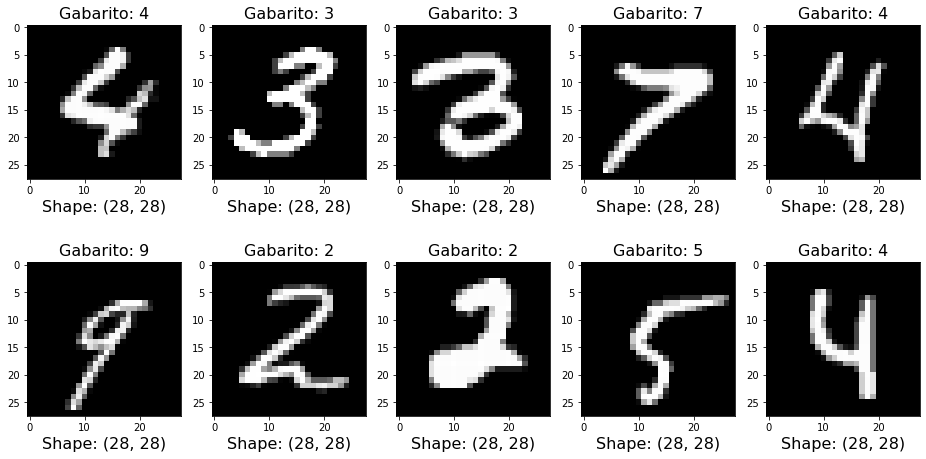

In [3]:
# Escolhe exemplos aleatórios
indices = np.random.randint(0, 60000-1, 10)

# Plots
fig, axs = plt.subplots(nrows = 2, ncols = 5, figsize=(16, 8))

for i, idx in enumerate(indices):
    
    # Plota a imagem
    axs[i//5][i%5].imshow( train_images[idx], vmin=0, vmax=255, cmap="gray" )
    
    # Adiciona o gabarito como título
    axs[i//5][i%5].set_title( "Gabarito: {}".format(train_labels[idx]), fontsize = 16 )
    
    # Adiciona o shape como subtítulo
    axs[i//5][i%5].set_xlabel( "Shape: {}".format(train_images[idx].shape), fontsize = 16 )

## <span style="color:brown">3. Pre-processamento dos dados de entrada</span> <a class="anchor" id="3"></a>
***

* Como estamos utilizando Redes Neurais Convolucionais 2D, precisamos que a entrada seja seja um array tetradimensional (4D), sendo necessário adicionar uma dimensão para os canais.

* Para isso, podemos utilizar a função **reshape(shape)** que reorganiza um array para um determinado formato especificado desde que seja possível alocar todos os valores do array original para o novo formato.

* Além disso, como em uma imagem todos os pixels são valores entre 0 e 255, podemos pre-processar os dados de entrada a partir de uma simples divisão por 255, que garante que todos os dados estarão entre 0 e 1.

In [4]:
def preprocess_data(data):
    # Desfaz adiciona uma dimensão para os canais da imagem
    data = data.reshape((len(data), 28, 28, 1))
    # Normaliza os valores ao dividir pelo maior valor possível dentro das imagens.
    data = data.astype("float32")/255
    return data

preprocessed_train_images = preprocess_data(train_images)
preprocessed_test_images  = preprocess_data(test_images)

* <span style="color:blue">**a. Verifique as dimensões e a faixa de valores dos dados de treino e teste após o pré-processamento. Não é necessário verificar a faixa de valores para cada característica isoladamente.**</span>

In [6]:
print('Dimensão dos Dados após o Pré-processamento:\n--')
print('Dimensão das Imagens de Treinamento: ', preprocessed_train_images.shape)
print('Dimensão das Imagens de Teste: ', preprocessed_test_images.shape)

print('\nLimites dos Dados após o Pré-processamento:\n--')
print('Limite nos Dados de Treinamento: [{:.2f}, {:.2f}]'.format(np.min(preprocessed_train_images), np.max(preprocessed_train_images)))
print('Limite nos Dados de Treinamento: [{:.2f}, {:.2f}]'.format(np.min(preprocessed_test_images), np.max(preprocessed_test_images)))

Dimensão dos Dados após o Pré-processamento:
--
Dimensão das Imagens de Treinamento:  (60000, 28, 28, 1)
Dimensão das Imagens de Teste:  (10000, 28, 28, 1)

Limites dos Dados após o Pré-processamento:
--
Limite nos Dados de Treinamento: [0.00, 1.00]
Limite nos Dados de Treinamento: [0.00, 1.00]


* <span style="color:green">Observando a dimensão dos dados após a etapa de pré-processamento, é verificado que as imagens encontram-se binarizadas e em apenas um canal de imagem. Além disso, a imagem encontra-se em duas dimensões, etapa que difere do pré-processamento utilizado para uma Rede Neural Artificial comum, a qual a imagem necessita estar em apenas uma dimensão usando um procedimento chamado de "Achatamento".</span> 

## <span style="color:brown">4. Particionamento dos dados de treino</span> <a class="anchor" id="4"></a>
***

* Agora vamos criar uma partição de validação a partir do conjunto de treino para realizar uma validação cruzada. 

* Novamente vamos utilizar a função **train_test_split**, que separa dados e os seus respectivos gabaritos segundo uma fração especificada.

* Contudo, dessa vez utilizaremos o parâmetro **stratify**, que indica os rótulos associados aos dados fornecidos. Quando esse parâmetro é fornecido a função realiza o particionamento dos dados e mantém a proporção entre exemplos de uma mesma classe com relação aos dados originais.

In [8]:
# Fração escolhida para separar o mesmo número de instâncias do conjunto de testes
data_frac = preprocessed_test_images.shape[0] / preprocessed_train_images.shape[0]

# Criação do conjunto de validação
preprocessed_train_images, preprocessed_val_images, train_labels, val_labels = train_test_split(preprocessed_train_images, # Dados de treino
                                                                                                train_labels,              # Gabaritos de treino
                                                                                                test_size = data_frac,     # Proporção de dados p/ validação
                                                                                                stratify = train_labels,   # Dados de referência
                                                                                                random_state=42)           # Semente para garantir consistencia nos resultados

print("Treino:", preprocessed_train_images.shape, train_labels.shape)
print("Validação:", preprocessed_val_images.shape, val_labels.shape)

Treino: (50000, 28, 28, 1) (50000,)
Validação: (10000, 28, 28, 1) (10000,)


## <span style="color:brown">5. Pre-processamento dos gabaritos</span> <a class="anchor" id="5"></a>
***

* Nesse caso temos um problema multiclasse com 10 classes, sendo elas correspondentes aos números entre 0 e 9. Consequentemente, o modelo produzido terá 10 unidades de saída, uma para cada classe, e utilizará a função de ativação softmax.

* Para fornecer esses gabaritos para a rede durante o treinamento é necessário categorizar as saídas, para limitá-las ao intervalo [0, 1]. Para isso vamos utilizar a função to_categorical() disponível no próprio Keras.

In [9]:
categorical_train_labels = to_categorical(train_labels)
categorical_val_labels   = to_categorical(val_labels)
categorical_test_labels  = to_categorical(test_labels)

## <span style="color:brown">6. Construindo o modelo</span> <a class="anchor" id="6"></a>
***

Para construir o modelo usaremos a classe **Sequential**, que possibilita a construção de modelos sequenciais de forma bastante simples.
* A construção do modelo é feita a partir do seu instanciamento como objeto da classe seguido de chamadas à função **add()** para adicionar camadas.
* Como estamos construindo Redes Neurais Convolucionais, vamos utilizar as camadas **Input**, **Conv2D**, **MaxPooling2D**, **Dropout**, **Flatten** e **Dense**.
    * A camada Input cria a entrada da rede com **Input( shape )**
        * shape corresponde ao formato do tensor de entrada, no nosso caso será o número de características do nosso banco de dados (28, 28, 1);
    * A camada Conv2D pode ser chamada com **Conv2D( num_kernels, kernel_size, activation = 'linear' )**
        * num_kernels corresponde ao número de conjuntos de filtros aplicados, determina o número de mapas de características na saída;
        * kernel_size é uma tupla (altura, largura) que determina o tamanho dos filtros;
        * activation corresponde à função de ativação utilizada na camada;
    * A camada MaxPooling2D pode ser chamada com **MaxPooling2D( kernel_size )**
        * kernel_size é uma tupla (altura, largura) que determina o tamanho dos filtros;
    * A camada Dropout pode ser chamada com **Dropout( drop_chance )**
        * drop_chance é um float que determina a chance de dropout na camada;
    * A camada Flatten pode ser chamada com **Flatten( )**
        * Essa camada "achata" os volumes de dados dos tensores de imagens e transforma em um vetor coluna;
    * A camada Dense pode ser chamada com **Dense( n_unidades, activation = 'linear' )**
        * n_unidades corresponde ao número de neurônios da camada;
        * activation corresponde à função de ativação utilizada na camada;
        
        
* Algumas funções de ativação disponíveis são:
    * "linear"
    * "relu"
    * "sigmoid"
    * "softmax"
    * "tanh"


* Mais informações sobre a camada dense podem ser vistas em **https://keras.io/api/layers/core_layers/dense/**
* Mais informações sobre as ativações disponíveis podem ser vistas em **https://keras.io/api/layers/activations/**

* <span style="color:blue">**b. A função abaixo constroi um modelo de rede neural e utiliza a função summary() para apresentar um resumo das informações da rede neural produzida. Comente o que faz cada linha do código.**</span>
    * <span style="color:blue">Modifique parâmetros como o número de filtros de cada camada e/ou o formato do tensor de entrada e/ou o número de saídas.</span>
    * <span style="color:blue">Explique como o número de parâmetros de cada camada é calculado. Esse valor depende do tamanho das imagens de entrada?</span>

In [11]:
def build_model( input_shape, n_outputs ):
    '''
    Função que cconstrói o modelo baseado em Redes Neurais Convolucionais
    ''' 
     
    # instanciando um modelo sequencial de rede neural usando a API Keras  
    rede = Sequential()
    # adicionando uma camada de entrada com as dimensões 'input_shape'
    rede.add(layers.Input((input_shape)))
    
    # adicionando uma camada de convolução com 32 filtros, tamanho do kernel 2x2 e função de ativação relu
    rede.add(layers.Conv2D(filters=32, kernel_size=(3, 3), activation='relu'))
    # adicionando uma camada de pooling com um kernel 2x2
    rede.add(layers.MaxPooling2D(pool_size=(2, 2)))
    # adicionando uma camada de dropout com uma taxa de 30,0% dos neurônios zerados   
    rede.add(layers.Dropout(rate=0.30))
    
    # adicionando uma camada de convolução com 64 filtros, tamanho do kernel 3x3 e função de ativação relu
    rede.add(layers.Conv2D(filters=64, kernel_size=(3, 3), activation='relu'))
    # adicionando uma camada de pooling com um kernel 2x2
    rede.add(layers.MaxPooling2D(pool_size=(2, 2)))
    # adicionando uma camada de dropout com uma taxa de 25,0% dos neurônios zerados   
    rede.add(layers.Dropout(rate=0.25))
    
    # adicionando uma camada de achatamento para tornar os parâmetros da rede em um vetor 1-dimensional
    rede.add(layers.Flatten())
    # conectando uma camada densa com 128 neurônios e função de ativação relu
    rede.add(layers.Dense(units=128, activation="relu"))
    # adicionando uma camada de saída com 'n_outputs' neurônios e função de ativação softmax 
    rede.add(layers.Dense(units=n_outputs, activation = "softmax"))
    
    return rede

model = build_model( (28, 28, 1), 10 )
model.summary()

Model: "sequential_1"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv2d_2 (Conv2D)            (None, 26, 26, 32)        320       
_________________________________________________________________
max_pooling2d_2 (MaxPooling2 (None, 13, 13, 32)        0         
_________________________________________________________________
dropout_2 (Dropout)          (None, 13, 13, 32)        0         
_________________________________________________________________
conv2d_3 (Conv2D)            (None, 11, 11, 64)        18496     
_________________________________________________________________
max_pooling2d_3 (MaxPooling2 (None, 5, 5, 64)          0         
_________________________________________________________________
dropout_3 (Dropout)          (None, 5, 5, 64)          0         
_________________________________________________________________
flatten_1 (Flatten)          (None, 1600)             

* <span style="color:green">Os comentários sobre o funcionamento da organização do modelo está destacado como comentários na função 'build_model'.</span>
* <span style="color:green">Os parâmetros em geral são pesos que são aprendidos durante o treinamento. São matrizes de peso que contribuem para o poder preditivo do modelo. Esses valores variam de acordo com a arquitetura de rede utilizada e também no formato dos dados de entrada. Além disso, algumas estratégias de otimização arquiteturais também impactam em mudanças no número de parâmetros. Tende em vista esses fatores, fica fácil entender que os parâmetros são obtidos através de cálculos realizados entre cada uma das camadas da rede e da forma na qual elas se conectam. Considerando a diversidade no modo como os neurônios estão conectados, os parâmetros de uma camada representam todos os pesos que devem ser aprendidos nesse ponto da rede, e o número total de parâmetros do modelo é a soma dos pesos presentes em cada uma das camadas, sendo esses pesos configurados como treináveis ou não (detalhes sobre esse procedimento são relativos ao estado da arte da transferência de aprendizagem).</span>

In [18]:
model = build_model( (28, 28, 1), 10 )
model.compile(optimizer=optimizers.Adam(lr=1e-3), 
              loss="categorical_crossentropy", 
              metrics=["acc"])
model.summary()

Model: "sequential_3"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv2d_6 (Conv2D)            (None, 26, 26, 32)        320       
_________________________________________________________________
max_pooling2d_6 (MaxPooling2 (None, 13, 13, 32)        0         
_________________________________________________________________
dropout_6 (Dropout)          (None, 13, 13, 32)        0         
_________________________________________________________________
conv2d_7 (Conv2D)            (None, 11, 11, 64)        18496     
_________________________________________________________________
max_pooling2d_7 (MaxPooling2 (None, 5, 5, 64)          0         
_________________________________________________________________
dropout_7 (Dropout)          (None, 5, 5, 64)          0         
_________________________________________________________________
flatten_3 (Flatten)          (None, 1600)             

## <span style="color:brown">7. Callbacks</span> <a class="anchor" id="7"></a>
*** 

* Dessa vez utilizaremos uma das callbacks do Keras, o Model_Checkpoint.
* Essa função salva o modelo conforme o treinamento é executado à medida que os valores da variável monitorada melhoram, preservando sempre o modelo com os melhores valores obtidos.
* model_checkpoint = ModelCheckpoint( path, monitor = None, save_best_only = True, verbose = 1)
    * path é o caminho para o salvamento do modelo;
    * monitor é a variável que deve ser monitorada pelo callback;
    * save_best_only indica se só o melhor modelo deve ser salvo ou se todos os aumentos devem ser salvos;
    * verbose é o modo de texto, 1 indica para que o Keras avise quando um novo modelo for salvo;

In [19]:
model_checkpoint = callbacks.ModelCheckpoint("model.hdf5", monitor = "val_acc", save_best_only = True, verbose = 1)

## <span style="color:brown">8. Treinando o modelo</span> <a class="anchor" id="8"></a>
***

O treinamento é realizado a partir da função **fit**, que recebe dados de treino e de validação além de hiperparâmetros como o número de épocas e o tamanho dos lotes de dados (batchsize).

* **hist = model.fit( x = None, y = None, epochs = 1, batchsize = None, callbacks = [], validation_data = None, verbose = "auto")**
    * x corresponde aos dados de treino;
    * y corresponde aos gabaritos de treino;
    * epochs corresponde ao número de épocas de treinamento;
    * batchsize corresponde ao tamanho dos lotes entregues à rede de cada vez;
    * callbacks corresponde à lista de callbacks utilizada;
    * validation_data corresponde a uma tupla ( val_data, val_targets ) com os dados de validação;
    * verbose indica como a função deve reportar os resultados:
        * 0: modo silencioso, nenhum retorno em formato de texto;
        * 1: retorno a cada época e barra de progresso;
        * 2: retorno a cada época sem barra de progresso;
    * hist é um dicionário de retorno com os valores de loss e das métricas computadas para treino e validação;
    
    
    
* Lista de callbacks disponíveis: https://keras.io/api/callbacks/

In [20]:
history = model.fit(preprocessed_train_images, categorical_train_labels, 
                    epochs=10, batch_size=128, callbacks = [model_checkpoint], 
                    validation_data = (preprocessed_val_images, categorical_val_labels) )
history_dict = history.history

Epoch 1/10
391/391 [==============================] - ETA: 0s - loss: 0.2725 - acc: 0.9153- ET
Epoch 00001: val_acc improved from -inf to 0.97490, saving model to model.hdf5
391/391 [==============================] - 45s 116ms/step - loss: 0.2725 - acc: 0.9153 - val_loss: 0.0876 - val_acc: 0.9749
Epoch 2/10
391/391 [==============================] - ETA: 0s - loss: 0.0849 - acc: 0.9737
Epoch 00002: val_acc improved from 0.97490 to 0.98050, saving model to model.hdf5
391/391 [==============================] - 40s 101ms/step - loss: 0.0849 - acc: 0.9737 - val_loss: 0.0601 - val_acc: 0.9805
Epoch 3/10
391/391 [==============================] - ETA: 0s - loss: 0.0613 - acc: 0.9804
Epoch 00003: val_acc improved from 0.98050 to 0.98530, saving model to model.hdf5
391/391 [==============================] - 42s 107ms/step - loss: 0.0613 - acc: 0.9804 - val_loss: 0.0521 - val_acc: 0.9853
Epoch 4/10
391/391 [==============================] - ETA: 0s - loss: 0.0513 - acc: 0.9840
Epoch 00004: val_

## <span style="color:brown">9. Plotagens Gráficas</span> <a class="anchor" id="9"></a>
*** 

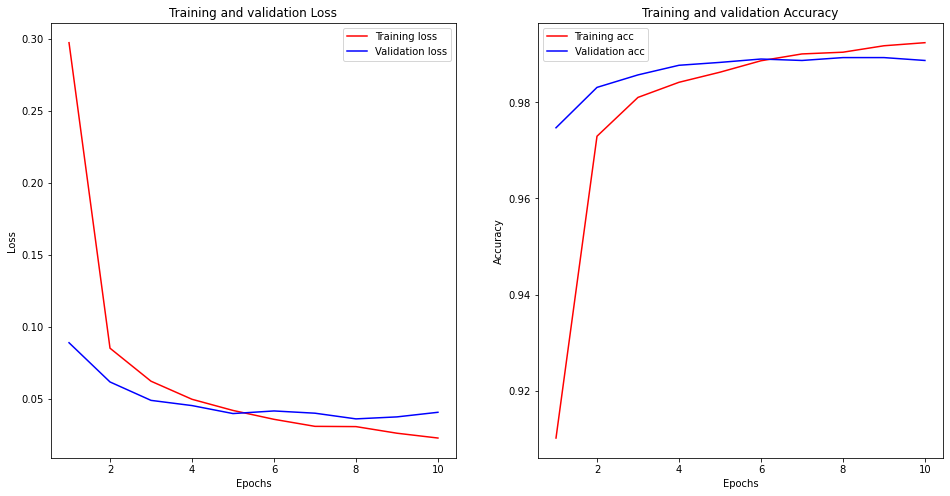

In [16]:
fig, axes = plt.subplots(1, 2, squeeze = False, figsize = (16,8))

# Loss
train_loss_values = history_dict['loss']
val_loss_values = history_dict['val_loss']

# Epochs
epochs = range(1, len(train_loss_values) + 1)

# Accuracy
train_acc_values = history_dict['acc']
val_acc_values = history_dict['val_acc']

ax = axes.flat[0]
ax.plot(epochs, train_loss_values, 'r', label='Training loss')
ax.plot(epochs, val_loss_values, 'b', label='Validation loss')
ax.set_title('Training and validation Loss')
ax.set_xlabel('Epochs')
ax.set_ylabel('Loss')
ax.legend()

ax = axes.flat[1]
ax.plot(epochs, train_acc_values, 'r', label='Training acc')
ax.plot(epochs, val_acc_values, 'b', label='Validation acc')
ax.set_title('Training and validation Accuracy')
ax.set_xlabel('Epochs')
ax.set_ylabel('Accuracy')
ax.legend()

## <span style="color:brown">10. Testes com o Modelo</span> <a class="anchor" id="10"></a>
***

O teste do modelo pode ser realizado a partir da função **evaluate**, que recebe os dados de treino e retorna o valor de loss calculado para esse conjunto e os valores de cada métrica da lista fornecida durante a compilação do modelo. 

* É uma prática comum realizar ajustes no modelo com base no conjunto de validação e só utilizar o conjunto de testes após a definição dos hiperparâmetros definitivos.
* Como os hiperparâmetros são ajustados a partir dos resultados obtidos para o conjunto de validação, o modelo pode acabar. sobreajustando aos dados de validação, então é interessante mudar os dados desse conjunto com frequência.
* Para mudar os dados de validação basta alterar a semente na função train_test_split.
* Crie um novo modelo do zero após a realização de mudanças nos conjuntos de treino/validação.

* <span style="color:blue">**c. As Redes Convolucionais obtiveram melhores resultados que as Redes Neurais Artificiais nesse banco de dados? Alguma das Redes Neurais Artificiais produzidas na parte 1 obtiveram resultados comparáveis?**</span>

In [21]:
test_loss, test_acc = model.evaluate(preprocessed_test_images, categorical_test_labels)

print("Test Accuracy:", 100*test_acc, "%")
print("Acertos: {} - Erros: {}".format(round(len(preprocessed_test_images)*test_acc), 
                                       round(len(preprocessed_test_images)*(1-test_acc))))

313/313 [==============================] - 2s 7ms/step - loss: 0.0276 - acc: 0.9905
Test Accuracy: 99.04999732971191 %
Acertos: 9905 - Erros: 95


In [17]:
model.load_weights('model.hdf5')

test_loss, test_acc = model.evaluate(preprocessed_test_images, categorical_test_labels)

print("Test Accuracy:", 100*test_acc, "%")
print("Acertos: {} - Erros: {}".format(round(len(preprocessed_test_images)*test_acc), 
                                       round(len(preprocessed_test_images)*(1-test_acc))))

313/313 [==============================] - 3s 9ms/step - loss: 0.0257 - acc: 0.9919
Test Accuracy: 99.19000267982483 %
Acertos: 9919 - Erros: 81


|Experimentos Realizados|Acurácia - Treinamento (%)|Acurácia - Validação (%)|Acurácia - Teste (%)|
|:----------|:---------------------|:-------------------|:---------------|
|CNN - Pesos do Último Treinamento|99,27|98,69|99,05|
|CNN - Melhores Pesos com Base na Acurácia nos Dados de Validação|99,10|98,84|99,19|
|ANN - Pesos do Último Treinamento|99,04|97,47|97,51|
|ANN - Melhores Pesos com Base na Acurácia nos Dados de Validação|99,04|97,47|97,51|

* <span style="color:green">Os resultados obtidos após o treinamento da rede foi interessante. O primeiro procedimento consiste em utilizar os pesos obtidos na última etapa de treinameno (10º Época). Com esses valores, os resultados observados foram:</span>
    * <span style="color:green">**Acurácia nos Dados de Treinamento: 99,27%**</span>
    * <span style="color:green">**Acurácia nos Dados de Validação: 98,69%**</span>
    * <span style="color:green">**Acurácia nso dados de Teste: 99,05%**</span>  
<span style="color:green">Esses valores indicam que a rede apresentou um desempenho bom em cada um dos dos conjuntos de Treinamento, Validação e Teste, a qual não apresenta indícios de *overfitting*.</span>
* <span style="color:green">Um dos *callbacks* utilizado durante o treinamento da rede consiste em tentar salvar os melhores pesos obtidos durante a etapa de treinamento, com base nos dados de validação. Configurando esses pesos como padrão, os quais foram obtidos no treinamento da 8º época, os resultados observados foram:<span>
    * <span style="color:green">**Acurácia nos Dados de Treinamento: 99,10%**</span>
    * <span style="color:green">**Acurácia nos Dados de Validação: 98,84%**</span>
    * <span style="color:green">**Acurácia nso dados de Teste: 99,19%**</span>   
<span style="color:green">Esses valores indicam que a rede apresentou um desempenho superior, em relação aos pesos obtidos na 10º época de treinamento em cada um dos conjuntos de Validação e Teste. É interessante observar que a taxa de acurácia nos dados de Treinamento não se mostrou superior em relação aos pesos da 10º época, a qual indica que os novos pesos configurados é menos sobreajustado que o modelo anterior, apresentando uma maior capacidade de generalização.</span>
* <span style="color:green">Por fim, é interessante comparar os resultados obtidos utilizando Redes Neurais Convolucinais (CNN) com os resultados obtidos utilizando Redes Neurais Artificias tradicionais (ANN). Os resultados obtidos para as ANN são observados a seguir:</span>
    * <span style="color:green">**Acurácia nos Dados de Treinamento: 99,04%**</span>
    * <span style="color:green">**Acurácia nos Dados de Validação: 97,47%**</span>
    * <span style="color:green">**Acurácia nso dados de Teste: 97,51%**</span>   
<span style="color:green">Esses valores indicam que a rede apresentou o menor desempenho em relação aos três testes realizados, Isso se justifica pela capacida das CNNs extrairem melhor as características de imagens do que ANNs tradicionais. Além disso, as CNNs são capazes de detectar objetos com mais independência da textura, distância focal e ângulos, o que permite uma melhor capacidade de generalização.</span>

## <span style="color:brown">11. Visualização dos Resultados</span> <a class="anchor" id="11"></a>
***

In [23]:
def show_results(xtest, ytest, ypred, num = 25, tipo = "rand"):
    
    if tipo == "acertos":
        fltr_idx = [i for i in range(xtest.shape[0]) if ypred[i] == ytest[i]]
    else:
        fltr_idx = [i for i in range(xtest.shape[0]) if ypred[i] != ytest[i]]
        
    indices = np.random.choice(fltr_idx, min(num, len(fltr_idx)), replace=False)
       
    rows = int(num/5)
    fig, axs = plt.subplots(nrows = rows, ncols = 5, figsize=(20, 4*rows))
    
    for i, idx in enumerate(indices):
        img = xtest[idx]
        if ypred[idx] == ytest[idx]:
            axs[i//5][i%5].set_title(str(ytest[idx]), color = "green", fontsize = 20)
        else:
            axs[i//5][i%5].set_title("Pred: {} - Gabarito: {}".format(ypred[idx], ytest[idx]), color = "red", fontsize = 20)
        
        axs[i//5][i%5].imshow(img, vmin=0, vmax=255, cmap = "gray")
    return

pred_labels = model.predict(preprocessed_test_images, verbose=1)
preds = np.argmax(pred_labels, axis = -1)

313/313 [==============================] - 2s 7ms/step


## <span style="color:brown">11.1. Acertos do Modelo</span> <a class="anchor" id="11.1"></a>
***

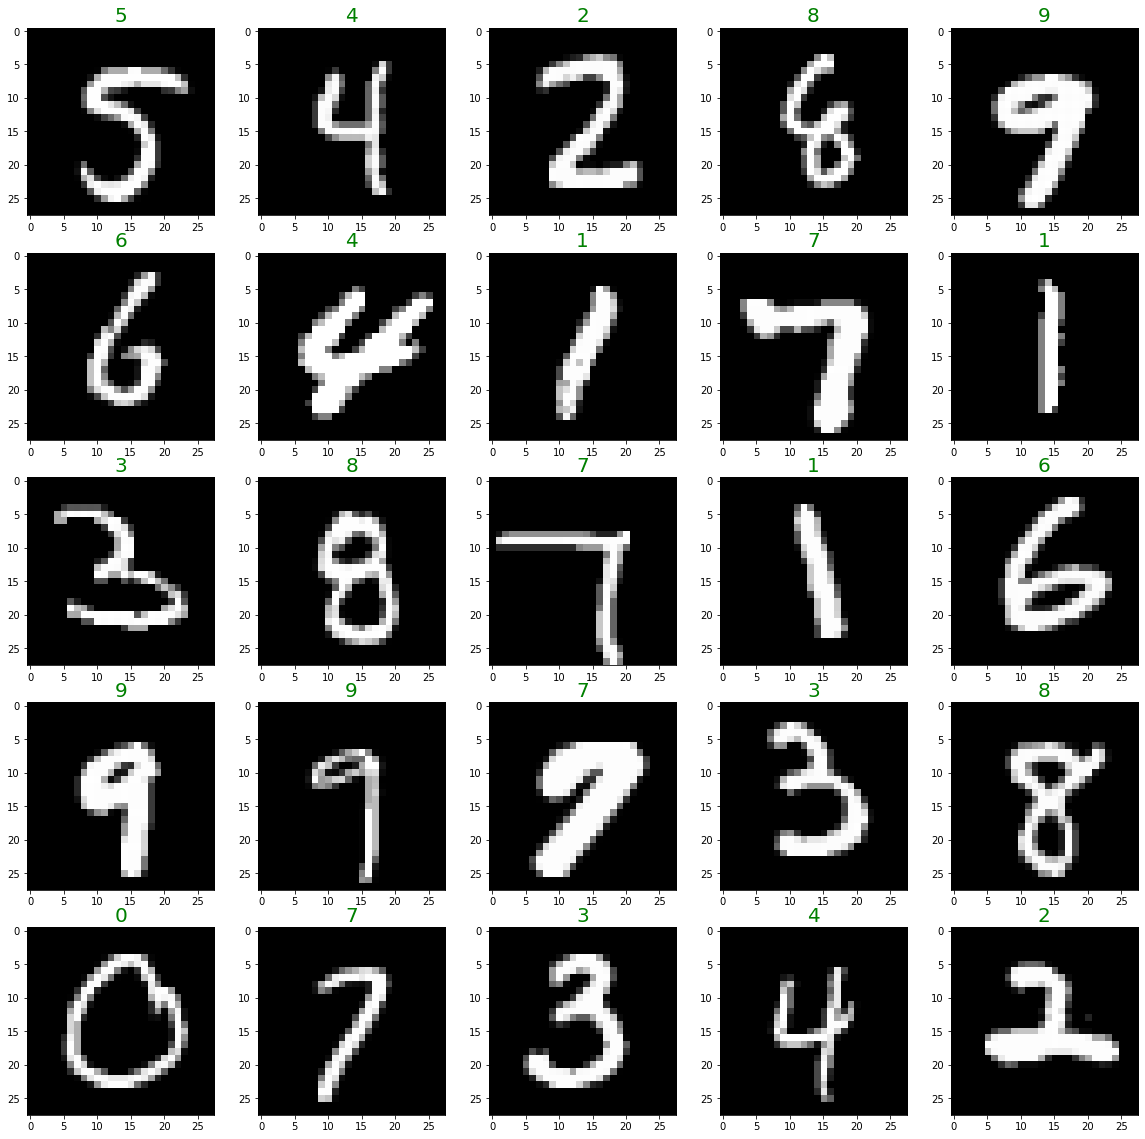

In [24]:
show_results(test_images, test_labels, preds, tipo = "acertos")

## <span style="color:brown">11.2. Erros do Modelo</span> <a class="anchor" id="11.2"></a>
***

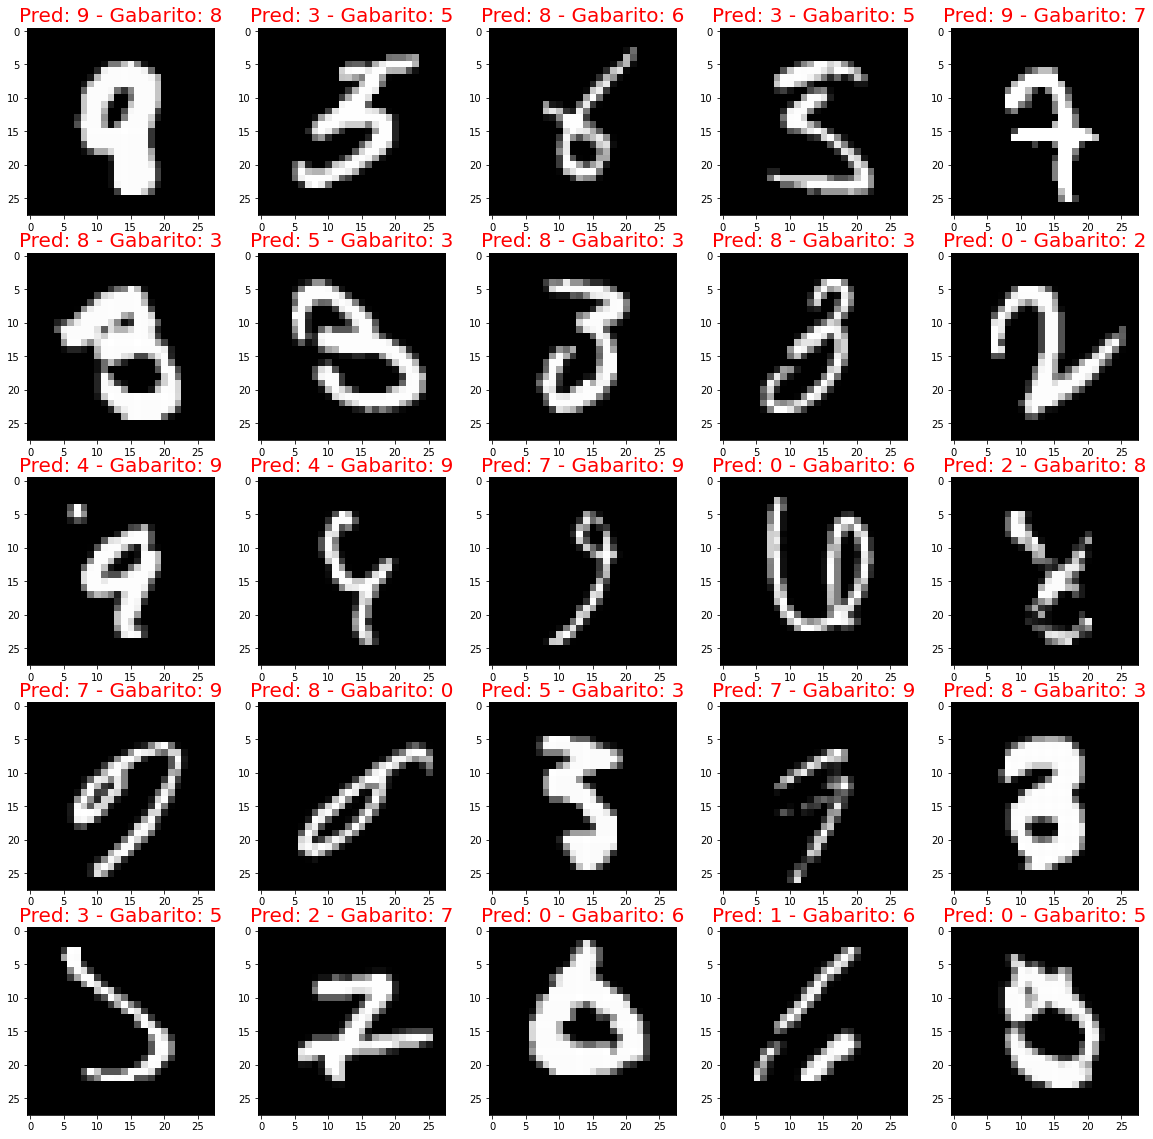

In [25]:
show_results(test_images, test_labels, preds, tipo = "erros")

***
![1_PKIwmv_VuRKnaECuKkIvtQ](https://user-images.githubusercontent.com/58775072/135723429-111df096-3b77-4ef5-8299-abcbe55d6c88.gif)